In [1]:
# Install XGBoost if not already installed
!pip install xgboost

# File: /home/sandbox/XGBoost_Model_Training.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)
import joblib

# Set random seed
np.random.seed(42)

# Load dataset
print("Loading dataset...")
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary11.xlsx')

# Define features and target
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']
target_col = 'Recharge_Class'

X = df[feature_cols].values
y = df[target_col].values

# Convert labels to 0-indexed (XGBoost requirement for multi-class)
y = y - 1  # Assuming classes are 1, 2, 3 → convert to 0, 1, 2

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Dataset shape: {X.shape}")
print(f"Train set: {X_train.shape[0]}, Test set: {X_test.shape[0]}")


Defaulting to user installation because normal site-packages is not writeable
Loading dataset...
Dataset shape: (51, 9)
Train set: 40, Test set: 11



✓ Model trained on training set!
Training Accuracy: 1.0000
Test Accuracy: 1.0000

Classification Report (Test Set):
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00         3
        High       1.00      1.00      1.00         8

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



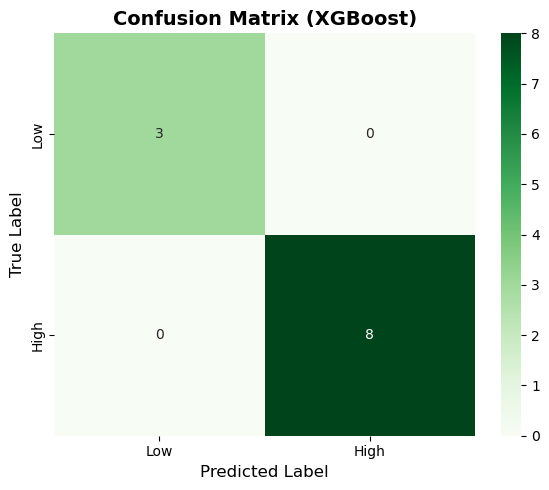

In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# -----------------------------
# Load dataset
# -----------------------------
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary11.xlsx')

# Features and target
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']
X = df[feature_cols]
y = df['Recharge_Class']

# -----------------------------
# Train-test split (80-20)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# Handle class imbalance
# # -----------------------------
# count_0 = (y_train == 0).sum()
# count_1 = (y_train == 1).sum()
# scale_pos_weight = count_0 / count_1 if count_1 > 0 else 1.0

# -----------------------------
# Initialize XGBoost classifier
# -----------------------------
xgb_final = xgb.XGBClassifier(
    n_estimators=80,
    max_depth=3,
    learning_rate=0.05,
    subsample=1,
    colsample_bytree=1,
    min_child_weight=1,
    gamma=0,
    reg_alpha=0,
    reg_lambda=1,
    scale_pos_weight=scale_pos_weight,
    objective='binary:logistic',  # correct for binary classification
    random_state=42,
    n_jobs=-1
)

# -----------------------------
# Train model
# -----------------------------
xgb_final.fit(X_train, y_train)
print("\n✓ Model trained on training set!")

# -----------------------------
# Predictions
# -----------------------------
y_pred_train = xgb_final.predict(X_train)
y_pred_test = xgb_final.predict(X_test)
y_pred_proba_test = xgb_final.predict_proba(X_test)[:, 1]

# -----------------------------
# Metrics
# -----------------------------
print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")

print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_pred_test, target_names=['Low', 'High']))

# -----------------------------
# Confusion matrix
# -----------------------------
cm = confusion_matrix(y_test, y_pred_test)
cm_labels = ['Low', 'High']

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=cm_labels,
    yticklabels=cm_labels,
    cbar=True
)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("Confusion Matrix (XGBoost)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -----------------------------
# Save model
# -----------------------------
# joblib.dump(xgb_final, r'D:\Thesis\Main\Models\XGBoost\XGBoost_Final_Model_80_20_Corrected.pkl')
# print("✓ Model saved as XGBoost_Final_Model_80_20_Corrected11.pkl")

# Save feature names for later use
joblib.dump(feature_cols, r'D:\Thesis\Main\Models\XGBoost\XGB_Final_Model_Features_name11.pkl')
print("✓ Feature names saved: feature_names.pkl")

In [4]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Test the model across 5 different "folds" of your data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(xgb_final, X, y, cv=cv, scoring='roc_auc')

print(f"Mean CV ROC AUC: {scores.mean():.4f} (+/- {scores.std():.4f})")

Mean CV ROC AUC: 0.9857 (+/- 0.0286)


In [7]:
# Visualize feature importance
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gain
xgb.plot_importance(xgb_final, importance_type='gain', ax=axes[0], max_num_features=9)
axes[0].set_title('Feature Importance (Gain)', fontsize=12, fontweight='bold')

# Weight
xgb.plot_importance(xgb_final, importance_type='weight', ax=axes[1], max_num_features=9)
axes[1].set_title('Feature Importance (Weight)', fontsize=12, fontweight='bold')

# Cover
xgb.plot_importance(xgb_final, importance_type='cover', ax=axes[2], max_num_features=9)
axes[2].set_title('Feature Importance (Cover)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('XGBoost_Feature_Importance.png', dpi=500, bbox_inches='tight')
plt.close()

print("\n✓ Feature importance plot saved: XGBoost_Feature_ImportanceNEW.png")



✓ Feature importance plot saved: XGBoost_Feature_ImportanceNEW.png


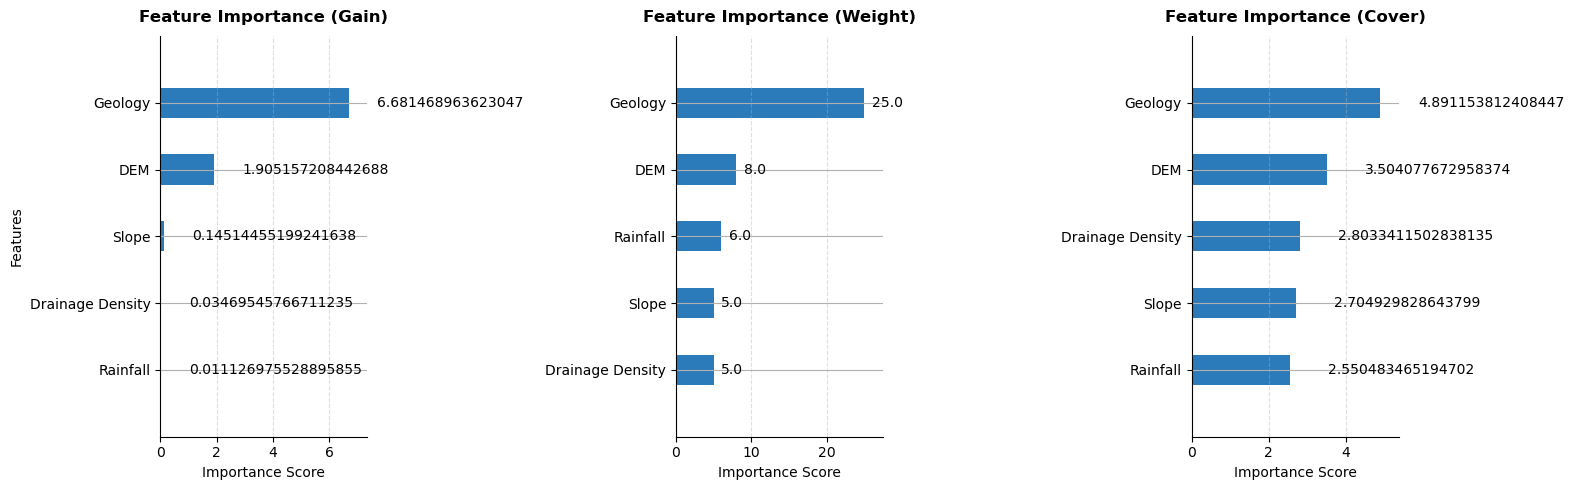


✓ Publication-quality feature importance plot saved successfully.


In [5]:
import matplotlib.pyplot as plt
import xgboost as xgb

# -----------------------------
# Journal/Thesis Quality Style
# -----------------------------
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# -----------------------------
# Create Figure
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

importance_types = ['gain', 'weight', 'cover']

titles = [
    'Feature Importance (Gain)',
    'Feature Importance (Weight)',
    'Feature Importance (Cover)'
]

# -----------------------------
# Plot Feature Importance
# -----------------------------
for i, imp_type in enumerate(importance_types):

    xgb.plot_importance(
        xgb_final,
        importance_type=imp_type,
        ax=axes[i],
        max_num_features=9,
        color='#2b7bba',
        height=0.45
    )

    # Clean feature names
    labels = [
        label.get_text().replace('_', ' ')
        for label in axes[i].get_yticklabels()
    ]

    axes[i].set_yticklabels(labels, fontsize=10)

    # Titles
    axes[i].set_title(
        titles[i],
        fontsize=12,
        pad=10
    )

    # Axis labels
    axes[i].set_xlabel(
        'Importance Score',
        fontsize=10
    )

    if i == 0:
        axes[i].set_ylabel(
            'Features',
            fontsize=10
        )
    else:
        axes[i].set_ylabel('')

    # Grid styling
    axes[i].grid(
        axis='x',
        linestyle='--',
        alpha=0.4
    )

    # Remove unnecessary borders
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# -----------------------------
# Layout and Save
# -----------------------------
plt.tight_layout()

plt.savefig(
    'XGBoost_Feature_Importance_Clean.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

print("\n✓ Publication-quality feature importance plot saved successfully.")

In [18]:
# Re-initialize model (same hyperparameters)
xgb_bin = xgb.XGBClassifier(
    n_estimators=30,
    max_depth=3,
    learning_rate=0.05,
    subsample=1,
    colsample_bytree=1,
    min_child_weight=1,
    gamma=0,
    reg_alpha=0,
    reg_lambda=1,
    scale_pos_weight=scale_pos_weight,
    objective='binary:logistic',
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    eval_metric='logloss'   # IMPORTANT for binary classification
)

# Train WITH eval_set
xgb_bin.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None, colsample_bytree=1,
              device=None, early_stopping_rounds=None, enable_categorical=False,
              eval_metric='logloss', feature_types=None, feature_weights=None,
              gamma=0, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=30, n_jobs=-1,
              num_parallel_tree=None, ...)

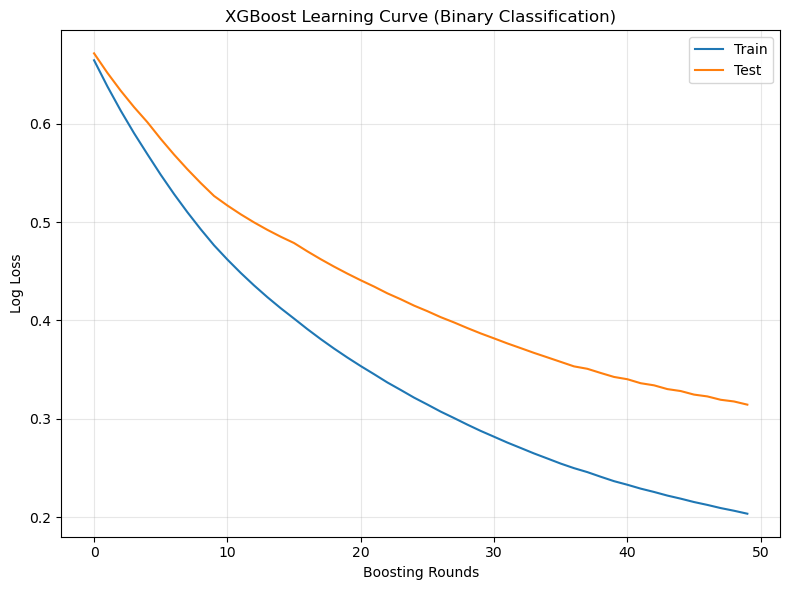

In [16]:
import matplotlib.pyplot as plt

# Get stored evaluation results
results = xgb_bin.evals_result()

epochs = len(results['validation_0']['logloss'])
x_axis = range(0, epochs)

# Plot
plt.figure(figsize=(8,6))
plt.plot(x_axis, results['validation_0']['logloss'], label='Train')
plt.plot(x_axis, results['validation_1']['logloss'], label='Test')

plt.legend()
plt.ylabel('Log Loss')
plt.xlabel('Boosting Rounds')
plt.title('XGBoost Learning Curve (Binary Classification)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('XGBoost_Learning_curve.png', dpi=500, bbox_inches='tight')
plt.show()


In [1]:
import pandas as pd
import numpy as np
import joblib
import xgboost as xgb
from sklearn.model_selection import cross_validate, StratifiedKFold

# -----------------------------
# Load your dataset
# -----------------------------
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary11.xlsx')
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']

X = df[feature_cols].values
y = df['Recharge_Class'].values

# -----------------------------
# K-Fold Cross-Validation
# # -----------------------------
# print("\n" + "="*80)
# print("K-FOLD CROSS-VALIDATION (XGBoost, K=5)")
# print("="*80)

xgb_cv = xgb.XGBClassifier(
    n_estimators=30,
    max_depth=4,
    learning_rate=0.05,
    subsample=1,
    colsample_bytree=1,
    min_child_weight=1,
    gamma=0,
    reg_alpha=0,
    reg_lambda=1,
    scale_pos_weight=scale_pos_weight,
    objective='binary:logistic',  # correct for binary classification
    random_state=42,
    n_jobs=-1
)

cv_results = cross_validate(
    xgb_cv, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted'],
    return_train_score=True,
    n_jobs=-1
)

print("\nCross-Validation Results (5-Fold):")
print(f"  Mean Train Accuracy: {cv_results['train_accuracy'].mean():.4f} ± {cv_results['train_accuracy'].std():.4f}")
print(f"  Mean Test Accuracy:  {cv_results['test_accuracy'].mean():.4f} ± {cv_results['test_accuracy'].std():.4f}")
print(f"  Mean Precision:      {cv_results['test_precision_weighted'].mean():.4f} ± {cv_results['test_precision_weighted'].std():.4f}")
print(f"  Mean Recall:         {cv_results['test_recall_weighted'].mean():.4f} ± {cv_results['test_recall_weighted'].std():.4f}")
print(f"  Mean F1-Score:       {cv_results['test_f1_weighted'].mean():.4f} ± {cv_results['test_f1_weighted'].std():.4f}")

# -----------------------------
# Save CV results
# # -----------------------------
# cv_df = pd.DataFrame(cv_results)
# cv_df.to_csv(r'D:\Thesis\Main\Models\XGBoost\XGBoost_CrossValidation_Results11.csv', index=False)
# print("\n✓ CV results saved: XGBoost_CrossValidation_Results11.csv")

# -----------------------------
# Fit model on full dataset and save as .pkl
# -----------------------------
xgb_cv.fit(X, y)
joblib.dump(xgb_cv, r'D:\Thesis\Main\Models\XGBoost\XGBoost_KFold_Model11.pkl')
print("✓ XGBoost K-Fold model saved: XGBoost_KFold_Model11.pkl")


# Save feature names for later use
joblib.dump(feature_cols, r'D:\Thesis\Main\Models\XGBoost\XGB_Final_Model_Features_name111.pkl')
print("✓ Feature names saved: feature_names.pkl")



K-FOLD CROSS-VALIDATION (XGBoost, K=5)


NameError: name 'scale_pos_weight' is not defined


✓ Model trained on training set!
Training Accuracy: 0.9500
Test Accuracy: 0.9091

Classification Report (Test Set):
              precision    recall  f1-score   support

         Low       1.00      0.67      0.80         3
        High       0.89      1.00      0.94         8

    accuracy                           0.91        11
   macro avg       0.94      0.83      0.87        11
weighted avg       0.92      0.91      0.90        11



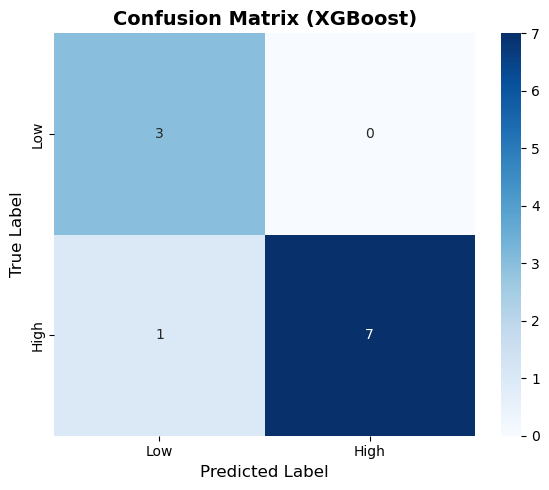

✓ Model saved as XGBoost_Final_Model.pkl


In [152]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import joblib

# -----------------------------
# Load your dataset
# -----------------------------
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary1.xlsx')

# Features and target
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']
X = df[feature_cols]
y = df['Recharge_Class']

# -----------------------------
# Train-test split (80-20)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# Handle class imbalance
# -----------------------------
count_0 = (y_train == 0).sum()
count_1 = (y_train == 1).sum()
scale_pos_weight = count_0 / count_1 if count_1 > 0 else 1.0

# -----------------------------
# Initialize XGBoost classifier
# -----------------------------
xgb_final = xgb.XGBClassifier(
    n_estimators=30,
    max_depth=3,
    learning_rate=0.05,
    subsample=1,
    colsample_bytree=1,
    min_child_weight=1,
    gamma=0,
    reg_alpha=0,
    reg_lambda=1,
    objective='multi:softmax',
    num_class=len(np.unique(y)),
    random_state=42,
    n_jobs=-1
)

# -----------------------------
# Train on training set only
# -----------------------------
xgb_final.fit(X_train, y_train)
print("\n✓ Model trained on training set!")

# -----------------------------
# Evaluate on test set
# -----------------------------
y_pred_test = xgb_final.predict(X_test)
y_pred_train = xgb_final.predict(X_train)

print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")

print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_pred_test, target_names=['Low', 'High']))


# Define class labels (since 0 = Low, 1 = High)
cm_labels = ['Low', 'High']

# Plot heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=cm_labels,
    yticklabels=cm_labels,
    cbar=True
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("Confusion Matrix (XGBoost)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -----------------------------
# Save model
# -----------------------------
joblib.dump(xgb_final, r'D:\Thesis\Main\Models\XGBoost\XGBoost_Final_Model.pkl')
print("✓ Model saved as XGBoost_Final_Model.pkl")
